# A first TestResult on a real slice of 50 cards

- **Level:** 1, Fundamentals
- **Prerequisites:** notebook 01 of this topic (install and open an artifact)
- **Reading time:** about 25 minutes

## Objectives

By the end of this notebook you can:

- call one engine test on your own arrays and read the `TestResult` it returns, field by field;
- say what the AUC, the Jeffreys test and the Brier score measure, and reproduce the first two with an independent check;
- explain why the same test gives a wide interval on 50 cards and a narrow one on 9,000, and why a green light on 50 cards is weak evidence;
- compare a recomputation with the committed row, naming the engine version that baked it.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import dataclasses
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is a slice of case C01 (retail credit-card PD) as Contraste commits it. The 30,000 cards come from the UCI Taiwan credit-card file (Yeh, 2009; CC BY 4.0, licence class `mirror-allowed`, https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients). The pipeline fitted a WoE scorecard (rung P1) on a training slice and scored a locked holdout of 9,000 cards. The holdout artifact keeps a **sample of 50 cards** with their outcome (`targets`, 1 for a default over the horizon) and the PD the scorecard gave them (`scorecard_pd`).

- **File read:** `data/derived/C01/holdout.json`, key `outputs.sample` for the 50 cards and the committed test rows in `tests` for the 9,000.
- **Why 50:** small enough to look at every card, large enough to run the tests. It is also a deliberate warning: validation on a small sample is the situation many validators are in.

The next cell loads the artifact and the 50 cards, and prints what they hold.

In [2]:
# Load the holdout artifact and the 50-card sample (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
holdout = json.loads((ROOT / "data" / "derived" / "C01" / "holdout.json").read_text(encoding="utf-8"))

sample = holdout["outputs"]["sample"]
ids = sample["ids"]
y = np.array(sample["targets"])
pd_hat = np.array(sample["scorecard_pd"])

print("cards in the sample:", len(ids), "| defaults:", int(y.sum()), "| default rate:", round(float(y.mean()), 4))
print("mean PD of the scorecard:", round(float(pd_hat.mean()), 4), "| expected defaults:", round(float(pd_hat.sum()), 2))
print("holdout cards:", holdout["outputs"]["n"], "| holdout defaults:", holdout["outputs"]["defaults"])
for k in range(3):
    print(ids[k], "default:", int(y[k]), "| PD:", round(float(pd_hat[k]), 4))

cards in the sample: 50 | defaults: 15 | default rate: 0.3
mean PD of the scorecard: 0.2534 | expected defaults: 12.67
holdout cards: 9000 | holdout defaults: 1991
TW00002 default: 1 | PD: 0.2379
TW00004 default: 0 | PD: 0.1489
TW00012 default: 0 | PD: 0.0952


## Method

Every engine test is a function that takes your arrays and an optional policy, and returns a `TestResult`: the record of one test on one model and one sample. We call three tests. First we create the policy they will read, the engine's packaged default.

In [3]:
# The packaged default policy; it is the object that will turn p-values into lights
policy = rv.default_policy()
print("policy:", policy.label)
print("tests with a threshold:", len(policy.thresholds))

policy: riskvalidation-default 2026.10.1
tests with a threshold: 48


### Step 1: the AUC, a measure of ranking

The area under the ROC curve is the probability that a randomly chosen defaulter was given a higher PD than a randomly chosen non-defaulter, counting ties as one half (Hanley and McNeil, 1982):

$$\mathrm{AUC} = P(\hat p_{\text{default}} > \hat p_{\text{non-default}}) + \tfrac12\, P(\hat p_{\text{default}} = \hat p_{\text{non-default}})$$

An AUC of 0.5 ranks no better than chance and 1 ranks perfectly. The engine's `disc_auc` returns it with its standard error and a 95% interval (the ECB's variance formula, ECB 2019, Annex 1, section 3.1). The next cell makes the call and reads the result.

In [4]:
# One call, one TestResult: the AUC of the scorecard on the 50 cards
from riskvalidation.validation import disc_auc

auc = disc_auc(pd_hat, y, policy=policy, model_id="P1-scorecard")
print("test_id:", auc.test_id)
print("AUC:", round(auc.metric, 6), "| gini:", round(auc.extras["gini"], 6))
print("standard error:", round(auc.extras["se"], 6))
print("95% interval:", round(auc.extras["ci95_low"], 4), "to", round(auc.extras["ci95_high"], 4))
print("light:", auc.light.value)
print("note:", auc.notes)

test_id: disc.auc
AUC: 0.775238 | gini: 0.550476
standard error: 0.065765
95% interval: 0.6463 to 0.9041
light: not_evaluated
note: policy riskvalidation-default 2026.10.1 holds no thresholds for this test; no light assigned


The definition makes a check possible: compare every defaulter with every non-defaulter and count how often the defaulter got the higher PD. This is a check of the definition on 50 cards, not a second implementation of the test; the engine remains the method.

In [5]:
# Check the definition by counting the pairs of a defaulter and a non-defaulter
defaulters = pd_hat[y == 1]
others = pd_hat[y == 0]
pairs = int(len(defaulters) * len(others))
concordant = (defaulters[:, None] > others[None, :]).mean()
ties = (defaulters[:, None] == others[None, :]).mean()

print("pairs compared:", pairs)
print("AUC from the pairs:", round(float(concordant + 0.5 * ties), 6))
print("equal to the engine:", bool(np.isclose(concordant + 0.5 * ties, auc.metric)))

pairs compared: 525
AUC from the pairs: 0.775238
equal to the engine: True


### Step 2: the Jeffreys test, a test of the level

The AUC says nothing about whether the PDs are the right size. The Jeffreys test asks it for a whole portfolio. Its null hypothesis is that the PD applied is greater than or equal to the true PD; it rejects when the observed defaults are too many for that. With $D$ defaults among $N$ obligors and an applied PD, the one-sided p-value is the Beta distribution function with a Jeffreys prior (Brown, Cai and DasGupta, 2001; ECB 2019, section 2.5.3.1):

$$p = F_{\mathrm{Beta}(D + 1/2,\; N - D + 1/2)}(\mathrm{PD})$$

A small p means more defaults than the PD allows: the model under-estimates risk. The next cell calls `pd_jeffreys` with the number of cards, the number of defaults and the mean PD, and prints every field of the `TestResult`.

In [6]:
# Call the Jeffreys test on the portfolio of 50 cards and print every field of the result
from riskvalidation.validation import pd_jeffreys

n_cards, n_defaults, mean_pd = len(y), int(y.sum()), float(pd_hat.mean())
jeffreys = pd_jeffreys(n=n_cards, d=n_defaults, pd=mean_pd, policy=policy, model_id="P1-scorecard", segment="portfolio")
for field in dataclasses.fields(jeffreys):
    value = getattr(jeffreys, field.name)
    if field.name in ("h0", "reference", "inputs_hash"):
        value = str(value)[:70] + "..."
    print(f"{field.name:14s} {value}")

test_id        pd.jeffreys
h0             the PD applied at the start of the period is greater than or equal to ...
reference      ECB (2019), Instructions for reporting the validation results of inter...
policy_version riskvalidation-default 2026.10.1
light          Light.GREEN
statistic      0.3
p_value        0.22107631615199014
metric         None
alternative    the true PD exceeds the PD applied (underestimation)
alpha_amber    0.05
alpha_red      0.01
n              50
n_events       15
model_id       P1-scorecard
segment        portfolio
inputs_hash    4f49ee00f88bc072ac80a946b765f9bbdb951ef86de747524f1db70505660607...
notes          
extras         {'pd_applied': 0.25341795330732486, 'default_rate': 0.3, 'posterior_q025': 0.1868771325356566, 'posterior_q975': 0.4355279077018387}


The same p-value from an independent implementation: the Beta distribution function of SciPy, at the pinned version. Agreement to the last digits shows that the engine's number is the formula above and nothing else.

In [7]:
# Reproduce the p-value with SciPy's Beta distribution function
p_scipy = stats.beta.cdf(mean_pd, n_defaults + 0.5, n_cards - n_defaults + 0.5)
print("p-value, SciPy:", round(float(p_scipy), 10))
print("p-value, engine:", round(jeffreys.p_value, 10))
print("equal:", bool(np.isclose(p_scipy, jeffreys.p_value)))
print("expected defaults at the mean PD:", round(n_cards * mean_pd, 2), "| observed:", n_defaults)

p-value, SciPy: 0.2210763162
p-value, engine: 0.2210763162
equal: True
expected defaults at the mean PD: 12.67 | observed: 15


### Step 3: the Brier score, a measure of the forecast

The Brier score is the mean squared error of the PD as a forecast of the 0/1 outcome (Brier, 1950; Murphy, 1973): lower is better, and the engine splits it into a reliability part (how far the PDs are from the observed rates), a resolution part (how well they separate) and the uncertainty of the outcome itself. The three parts add up to the score only when the PDs are constant within each bin, where the decomposition is exact; with continuous PDs they do not, and the engine records whether it was exact in `extras["decomposition_exact"]`, which the next cell prints. It is descriptive: it has no null hypothesis and the default policy holds no threshold for it.

In [8]:
# Call the Brier score on the 50 cards and read its decomposition
from riskvalidation.validation import pd_brier

brier = pd_brier(y, pd_hat, policy=policy, model_id="P1-scorecard", segment="portfolio")
print("Brier score:", round(brier.metric, 6))
for key in ("reliability", "resolution", "uncertainty", "brier_skill"):
    print(f"{key:12s} {round(brier.extras[key], 6)}")
print("decomposition exact:", brier.extras["decomposition_exact"])
print("light:", brier.light.value)

Brier score: 0.189701
reliability  0.031935
resolution   0.058
uncertainty  0.21
brier_skill  0.09666
decomposition exact: False
light: not_evaluated


### Step 4: the same tests on the 9,000 committed cards

The holdout artifact commits these three tests for the whole holdout of 9,000 cards. The next cell puts the 50-card result beside the committed row, with the engine version that baked the artifact next to the installed one, as notebook 01 prescribes.

In [9]:
# Put the 50-card results beside the committed rows of the 9,000-card holdout
committed = {
    row["test_id"]: row
    for row in holdout["tests"]
    if row["model_id"] == "P1-scorecard" and row["segment"] == "portfolio"
}
print("baked by riskvalidation", holdout["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

auc_all = committed["disc.auc"]
jef_all = committed["pd.jeffreys"]
brier_all = committed["pd.brier"]
print(f"{'':22s} {'50 cards':>12s} {'9000 cards':>12s}")
print(f"{'AUC':22s} {auc.metric:12.4f} {auc_all['metric']:12.4f}")
print(f"{'AUC interval width':22s} {auc.extras['ci95_high'] - auc.extras['ci95_low']:12.4f} {auc_all['extras']['ci95_high'] - auc_all['extras']['ci95_low']:12.4f}")
print(f"{'Jeffreys p-value':22s} {jeffreys.p_value:12.4f} {jef_all['p_value']:12.4f}")
print(f"{'Jeffreys light':22s} {jeffreys.light.value:>12s} {jef_all['light']:>12s}")
print(f"{'Brier score':22s} {brier.metric:12.4f} {brier_all['metric']:12.4f}")

baked by riskvalidation 1.0.1 | installed 1.0.1
                           50 cards   9000 cards
AUC                          0.7752       0.7587
AUC interval width           0.2578       0.0253
Jeffreys p-value             0.2211       0.3095
Jeffreys light                green        green
Brier score                  0.1897       0.1393


The last cell draws the two lessons. On the left, the PD the scorecard gave to the 50 cards by outcome: defaulters tend to sit higher, which is the ranking the AUC measures. On the right, the AUC with its 95% interval on 50 cards and on 9,000: the point estimates are close, the uncertainty is not.

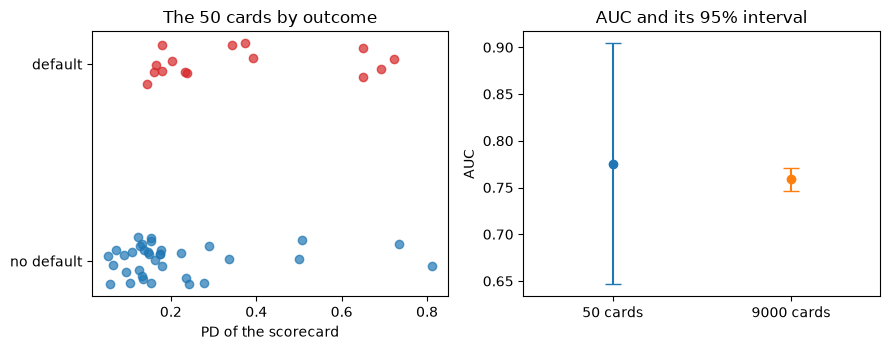

In [10]:
# Draw the PD by outcome and the AUC with its interval at the two sample sizes
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.6))

rng = np.random.default_rng(0)
for outcome, color in ((0, "tab:blue"), (1, "tab:red")):
    values = pd_hat[y == outcome]
    left.scatter(values, outcome + rng.uniform(-0.12, 0.12, len(values)), color=color, alpha=0.7)
left.set_yticks([0, 1])
left.set_yticklabels(["no default", "default"])
left.set_xlabel("PD of the scorecard")
left.set_title("The 50 cards by outcome")

for position, (label, row) in enumerate((("50", auc.extras | {"metric": auc.metric}), ("9000", auc_all["extras"] | {"metric": auc_all["metric"]}))):
    right.errorbar(position, row["metric"], yerr=[[row["metric"] - row["ci95_low"]], [row["ci95_high"] - row["metric"]]], fmt="o", capsize=6)
right.set_xticks([0, 1])
right.set_xticklabels(["50 cards", "9000 cards"])
right.set_ylabel("AUC")
right.set_title("AUC and its 95% interval")
right.set_xlim(-0.5, 1.5)
fig.tight_layout()
plt.show()

## Results

- **Ranking.** The scorecard ranks the 50 cards well: the AUC is 0.775 by the engine and by the pair count, and the committed AUC on 9,000 cards is 0.759. The interval on 50 cards, about 0.65 to 0.90, contains the committed value; the interval on 9,000 cards is about 0.75 to 0.77. The ranking is real and the 50-card estimate is imprecise.
- **Level.** The Jeffreys p-value on 50 cards is 0.22 and on 9,000 cards 0.31, both green under the default policy. On 50 cards the green light is weak evidence: with only 15 defaults the test has little power to reject a PD that is moderately too low. A green light is the absence of evidence against the model, not proof that the PDs are right.
- **Forecast.** The Brier score is 0.190 on 50 cards and 0.139 on 9,000. It has no light: it measures, and a validator reads it against the Brier score of a model that predicts the base rate (the `uncertainty` term). The parts printed above do not add up to the score here (0.032 minus 0.058 plus 0.210 is 0.184, against 0.190): the decomposition is not exact on these continuous PDs, so read the three parts as indicators, not as an identity.
- **What a `TestResult` gives you** that a bare number does not: the null hypothesis, the direction of the alternative, the policy that coloured it, the sample sizes, a hash of the inputs, and the source that defines the test. That is what makes a row of a validation report auditable.

What this notebook does not show: how the policy produced the colours (notebook 03), what happens when many tests run on one sample (notebook 04), or how the scorecard was built (topic 02).

## Summary

- One call returns one `TestResult`: the statistic or metric, the p-value, the null hypothesis, the policy label and light, the sample sizes, an inputs hash and the reference.
- The AUC measures ranking, the Jeffreys test measures the level of the PDs, the Brier score measures the forecast. A model can rank well and still be mis-sized, so a validator runs all of them.
- The same test on 50 cards and on 9,000 cards gives close point estimates and very different uncertainty; read the interval before the colour.
- A recomputation is compared with the committed row only after naming the engine version that baked it.

**What to try next.** Change the slice: take the first 25 cards, then all 50, and watch the AUC interval and the Jeffreys p-value move. Then read `docs/guides/03_read-a-validation-report.md` and continue with notebook 03.

## References

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Annex 1 (section 3.1) and section 2.5.3.1. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Hanley, J. A. and McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Brier, G. W. (1950), Monthly Weather Review 78(1), doi 10.1175/1520-0493(1950)078<0001:VOFEIT>2.0.CO;2, and Murphy, A. H. (1973), Journal of Applied Meteorology 12(4), as cited by the engine's `pd.brier` entry.
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients